In [1]:
from common import *

In [2]:
compute = False

## Intron

Ion counts with time

In [3]:
# Load binding motif data
ions = ['NA', 'MG']
df = pd.DataFrame()

# Replex
method = 'replex'
systems = ['7ez0', '7ez0_noion']
ff = 'mMg_tip3p'
replicates = [0, 1]
repids = range(8)

for ion in ions:
    for sys in systems:
        for rep, i in itertools.product(replicates, repids):
            _df = pd.read_parquet(
                PROJECT_DIR / f'replex/{sys}/{ff}/replicate{rep}/rep{i+8*rep:02d}/{ion}_motifs.parquet',
                columns=['time', 'index', 'n_inner', 'n_outer', 'inner_names'],
                
            )
            _df = _df.loc[_df['time'].astype(int) % 1000 == 0]
            _df = _df.assign(ion=ion, sim=f"{method}_{sys}_{ff}", system=sys, replicate=rep, repid=i)
            colvar = read_plumed(PROJECT_DIR / f'replex/{sys}/{ff}/replicate{rep}/rep{i+8*rep:02d}/bias.COLVAR.{i}')
            colvar['time'] = colvar['time'].astype(int)
            _df['reptemp'] = colvar.set_index('time').loc[_df['time'].astype(int), 'bias.index'].astype(int).values
            _df['time'] = _df['time'] / 1000  # ns

            df = pd.concat([df, _df])

# Plain MD
method = 'plain_md'
systems = ['7ez0', '7ez0_noion', '7ez0_nomg']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
replicates = range(8)

for ion in ions:
    for sys, ff in itertools.product(systems, forcefields):
        for rep in replicates:
            path = PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/rep{rep:02d}/{ion}_motifs.parquet'
            if not path.exists():
                continue
            _df = pd.read_parquet(
                path,
                columns=['time', 'index', 'n_inner', 'n_outer', 'inner_names'],
            )
            _df = _df.loc[_df['time'].astype(int) % 1000 == 0]
            _df = _df.assign(ion=ion, sim=f"{method}_{sys}_{ff}", system=sys, replicate=rep, repid=0)
            _df['reptemp'] = 0
            _df['time'] = _df['time'] / 1000  # ns

            df = pd.concat([df, _df])

In [4]:
df

,time,index,n_inner,n_outer,inner_names,ion,sim,system,replicate,repid,reptemp
0,0.0,269659,0,0,[],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
1,0.0,269660,0,0,[],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
2,0.0,269661,0,0,[],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
3,0.0,269662,1,11,[O2'],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
4,0.0,269663,0,0,[],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
1068173,600.0,269704,0,24,[],MG,plain_md_7ez0_noion_nMg_tip3p,7ez0_noion,7,0,0
1068174,600.0,269705,0,0,[],MG,plain_md_7ez0_noion_nMg_tip3p,7ez0_noion,7,0,0
1068175,600.0,269706,1,12,[OP2],MG,plain_md_7ez0_noion_nMg_tip3p,7ez0_noion,7,0,0
1068176,600.0,269707,1,13,[OP2],MG,plain_md_7ez0_noion_nMg_tip3p,7ez0_noion,7,0,0


Time evolution:

In [5]:
res = df.groupby(['ion', 'sim', 'system', 'replicate', 'repid', 'reptemp', 'time', 'n_inner']).size().unstack(fill_value=0).stack().reset_index(name='count')
res = res.query('n_inner > 0 and reptemp == 0').groupby(['ion', 'sim', 'system', 'replicate', 'time'])['count'].sum().reset_index(name='count').groupby(['ion', 'sim', 'system', 'time'])['count'].aggregate(['mean', 'sem'])
res

mean       sem
ion sim                         system     time                   
MG  plain_md_7ez0_mMg_tip3p     7ez0       0.0    20.500  0.188982
                                           1.0    20.250  0.250000
                                           2.0    20.125  0.226582
                                           3.0    20.125  0.226582
                                           4.0    20.250  0.250000
...                                                  ...       ...
NA  replex_7ez0_noion_mMg_tip3p 7ez0_noion 196.0  23.500  1.500000
                                           197.0  23.000  2.000000
                                           198.0  18.000  1.000000
                                           199.0  18.500  0.500000
                                           200.0  19.000  2.000000

[7215 rows x 2 columns]

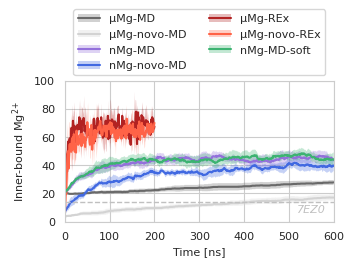

In [6]:
n_inner_pdb = 14

fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

labels, handles = [], []
for sim in simselection:
    group = res.loc['MG', sim, :, :]
    if group.size == 0:
        continue
    x = group.index.get_level_values("time")
    y = group["mean"]
    err = group["sem"]
    
    lower = y - 1.96*err
    upper = y + 1.96*err
    line, = ax.plot(x, y, color=simcolors[sim])
    patch = ax.fill_between(x, lower, upper, alpha=0.3, color=simcolors[sim], edgecolor='none')
    labels.append(simlabels[sim])
    handles.append((line, patch))

ax.set_ylabel(f"Inner-bound {ionlabels['MG']}")
ax.set_xlabel("Time [ns]")
ax.legend(handles, labels, ncol=2, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))
ax.set_ylim(0, 100)
ax.set_xlim(0, 600)
ax.axhline(n_inner_pdb, ls='dashed', lw=1, color='silver')
ax.text(550, n_inner_pdb - 2, '7EZ0', style='italic', color='silver', ha='center', va='top')

fig.savefig(f'figures/inner_bound_mg_timeseries{suffix}.pdf')



/tmp/ipykernel_2258/829720385.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  popt, pcov = curve_fit(exponential_func, x, y, p0=(y[0], y[-1], 1))
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/pandas/core/indexes/base.py:952: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*new_inputs, **kwargs)


plain_md_7ez0_mMg_tip3p n(0) = 19.6, n(inf) = 60.3, k = 3.75e-04 ns⁻¹
plain_md_7ez0_noion_mMg_tip3p n(0) = 4.4, n(inf) = 29.3, k = 1.17e-03 ns⁻¹
plain_md_7ez0_nMg_tip3p n(0) = 21.5, n(inf) = 44.7, k = 1.44e-02 ns⁻¹
plain_md_7ez0_noion_nMg_tip3p n(0) = 11.0, n(inf) = 38.7, k = 8.92e-03 ns⁻¹
replex_7ez0_mMg_tip3p n(0) = 21.4, n(inf) = 67.1, k = 1.41e-01 ns⁻¹
replex_7ez0_noion_mMg_tip3p n(0) = 13.2, n(inf) = 63.7, k = 1.04e-01 ns⁻¹
plain_md_7ez0_nMg_tip3p_soft n(0) = 21.3, n(inf) = 45.0, k = 1.63e-02 ns⁻¹


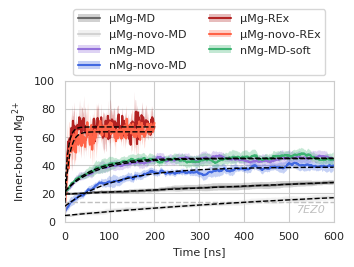

In [7]:
from scipy.optimize import curve_fit

def exponential_func(x, a0, amax, k):
    return a0 + (amax - a0)*(1 - np.exp(-k*x))

n_inner_pdb = 14

fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

labels, handles = [], []
for sim in simselection:
    group = res.loc['MG', sim, :, :]
    if group.size == 0:
        continue
    x = group.index.get_level_values("time")
    y = group["mean"]
    err = group["sem"]
    
    popt, pcov = curve_fit(exponential_func, x, y, p0=(y[0], y[-1], 1))
    print(sim, f"n(0) = {popt[0]:.1f}, n(inf) = {popt[1]:.1f}, k = {popt[2]:.2e} ns⁻¹")

    lower = y - 1.96*err
    upper = y + 1.96*err
    line, = ax.plot(x, y, color=simcolors[sim])
    ax.plot(x, exponential_func(x, *popt), color='k', ls='dashed', lw=1, zorder=10)
    patch = ax.fill_between(x, lower, upper, alpha=0.3, color=simcolors[sim], edgecolor='none')
    labels.append(simlabels[sim])
    handles.append((line, patch))

ax.set_ylabel(f"Inner-bound {ionlabels['MG']}")
ax.set_xlabel("Time [ns]")
ax.legend(handles, labels, ncol=2, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))
ax.set_ylim(0, 100)
ax.set_xlim(0, 600)
ax.axhline(n_inner_pdb, ls='dashed', lw=1, color='silver')
ax.text(550, n_inner_pdb - 2, '7EZ0', style='italic', color='silver', ha='center', va='top')

fig.savefig(f'figures/inner_bound_mg_timeseries{suffix}_expfit.pdf')



/tmp/ipykernel_2258/4136900192.py:25: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


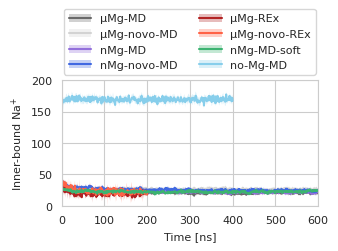

In [8]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

labels, handles = [], []
for sim in simselection:
    group = res.loc['NA', sim, :, :]
    if group.size == 0:
        continue
    x = group.index.get_level_values("time")
    y = group["mean"]
    err = group["sem"]
    
    lower = y - 1.96*err
    upper = y + 1.96*err
    line, = ax.plot(x, y, color=simcolors[sim])
    patch = ax.fill_between(x, lower, upper, alpha=0.3, color=simcolors[sim], edgecolor='none')
    labels.append(simlabels[sim])
    handles.append((line, patch))

ax.set_ylabel(f"Inner-bound {ionlabels['NA']}")
ax.set_xlabel("Time [ns]")
ax.legend(handles, labels, ncol=2, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))
ax.set_ylim(0, 200)
ax.set_xlim(0, 600)

plt.tight_layout()
fig.savefig('figures/inner_bound_na_timeseries.pdf')

In [9]:
res = df.query('n_inner == 0 and n_outer > 0 and reptemp == 0').groupby(['ion', 'sim', 'system', 'replicate', 'repid', 'reptemp', 'time']).size().reset_index(name='count')
res = res.groupby(['ion', 'sim', 'system', 'time'])['count'].aggregate(['mean', 'sem'])

/tmp/ipykernel_2258/1841448389.py:29: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


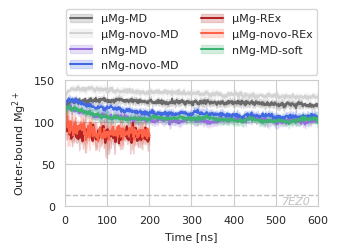

In [10]:
n_outer_pdb = 13

fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

labels, handles = [], []
for sim in simselection:
    group = res.loc['MG', sim, :, :]
    if group.size == 0:
        continue    
    x = group.index.get_level_values("time")
    y = group["mean"]
    err = group["sem"]
    
    lower = y - 1.96*err
    upper = y + 1.96*err
    line, = ax.plot(x, y, color=simcolors[sim])
    patch = ax.fill_between(x, lower, upper, alpha=0.2, color=simcolors[sim])
    labels.append(simlabels[sim])
    handles.append((line, patch))

ax.set_ylabel("Outer-bound Mg$^{2+}$")
ax.set_xlabel("Time [ns]")
ax.legend(handles, labels, ncol=2, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))
ax.set_ylim(0, 150)
ax.set_xlim(0, 600)
ax.axhline(n_outer_pdb, ls='dashed', lw=1, color='silver')
ax.text(550, n_outer_pdb - 2, '7EZ0', style='italic', color='silver', ha='center', va='top')

plt.tight_layout()
fig.savefig('figures/outer_bound_mg_timeseries.pdf')


/tmp/ipykernel_2258/1830964651.py:25: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


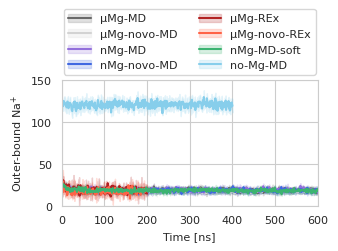

In [11]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

labels, handles = [], []
for sim in simselection:
    group = res.loc['NA', sim, :, :]
    if group.size == 0:
        continue
    x = group.index.get_level_values("time")
    y = group["mean"]
    err = group["sem"]
    
    lower = y - 1.96*err
    upper = y + 1.96*err
    line, = ax.plot(x, y, color=simcolors[sim])
    patch = ax.fill_between(x, lower, upper, alpha=0.2, color=simcolors[sim])
    labels.append(simlabels[sim])
    handles.append((line, patch))

ax.set_ylabel("Outer-bound Na$^{+}$")
ax.set_xlabel("Time [ns]")
ax.legend(handles, labels, ncol=2, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))
ax.set_ylim(0, 150)
ax.set_xlim(0, 600)

plt.tight_layout()
fig.savefig('figures/outer_bound_na_timeseries.pdf')

Inner site types

In [12]:
res = df.query("n_inner > 0 and reptemp == 0").explode('inner_names')[['ion', 'sim', 'time', 'replicate', 'repid', 'inner_names']]
res['t_start'] = res['sim'].map(simstart)
res = res.query("time > t_start")
res['inner_names'] = res['inner_names'].replace({'O1P': 'OP1', 'O2P': 'OP2'}).astype('category')
block_weight = res.groupby(['ion', 'sim', 'replicate', 'repid'])['time'].agg('nunique')
block_weight = block_weight / block_weight.groupby(['ion', 'sim']).sum() * block_weight.groupby(['ion', 'sim']).size()
res = res.groupby(['ion', 'sim', 'replicate', 'repid', 'inner_names'], observed=True).size().unstack(fill_value=0).stack().to_frame(name='count')
res['block_weight'] = block_weight
n_bootstrap = 200

In [13]:
count = res.groupby(['ion', 'sim', 'inner_names'], observed=False).apply(lambda x: np.average(x['count'], weights=x['block_weight']))
p = count / count.groupby(['ion', 'sim']).sum()

count_bs = res.groupby(['ion', 'sim', 'inner_names'], observed=False).apply(
    lambda x: np.average(x['count'].to_numpy()[None, :].repeat(n_bootstrap, axis=0), weights=np.random.dirichlet(x['block_weight'], 200), axis=1)
    )
p_bs = count_bs / count_bs.groupby(['ion', 'sim']).apply(lambda x: np.sum(x, axis=0))

result = pd.DataFrame({
    'p': p,
    'p_low': p_bs.apply(np.quantile, args=(0.025,)),
    'p_high': p_bs.apply(np.quantile, args=(0.975,)),
})


In [14]:
result

p     p_low    p_high
ion sim                         inner_names                              
MG  plain_md_7ez0_mMg_tip3p     C1'          0.000000  0.000000  0.000000
                                C2           0.000026  0.000011  0.000041
                                C2'          0.000000  0.000000  0.000000
                                C4           0.000000  0.000000  0.000000
                                C4'          0.000000  0.000000  0.000000
...                                               ...       ...       ...
NA  replex_7ez0_noion_mMg_tip3p O5'          0.006147  0.004458  0.008172
                                O6           0.043357  0.030138  0.060987
                                OP1          0.233792  0.187129  0.284642
                                OP2          0.233597  0.181080  0.292130
                                P            0.002136  0.001497  0.002771

[720 rows x 3 columns]

In [15]:
result['p_max'] = result.groupby(['ion', 'inner_names'], observed=False)['p'].transform('max')

In [16]:
result

p     p_low    p_high  \
ion sim                         inner_names                                 
MG  plain_md_7ez0_mMg_tip3p     C1'          0.000000  0.000000  0.000000   
                                C2           0.000026  0.000011  0.000041   
                                C2'          0.000000  0.000000  0.000000   
                                C4           0.000000  0.000000  0.000000   
                                C4'          0.000000  0.000000  0.000000   
...                                               ...       ...       ...   
NA  replex_7ez0_noion_mMg_tip3p O5'          0.006147  0.004458  0.008172   
                                O6           0.043357  0.030138  0.060987   
                                OP1          0.233792  0.187129  0.284642   
                                OP2          0.233597  0.181080  0.292130   
                                P            0.002136  0.001497  0.002771   

                                                p_max  
ion sim                         inner_names            
MG  plain_md_7ez0_mMg_tip3p     C1'          0.000000  
                                C2           0.000026  
                                C2'          0.000000  
                                C4           0.000000  
                                C4'          0.000000  
...                                               ...  
NA  replex_7ez0_noion_mMg_tip3p O5'          0.019445  
                                O6           0.094015  
                                OP1          0.253864  
                                OP2          0.260904  
                                P            0.003394  

[720 rows x 4 columns]

/tmp/ipykernel_2258/1442782733.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_2258/1442782733.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):


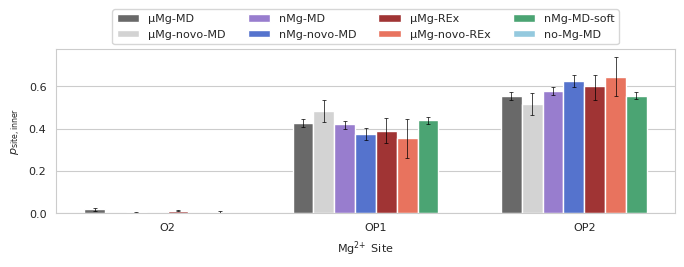

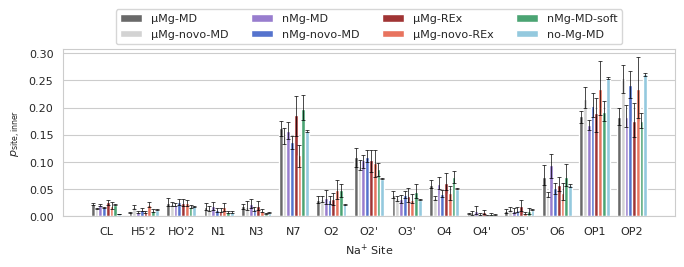

In [17]:
for ion in ['MG', 'NA']:
    fig, ax = plt.subplots(figsize=(17.1*cm, 6.5*cm))

    data = result.query('p_max > 0.01').loc[ion].rename(index=simlabels).reset_index()
    data['sim'] = data['sim'].astype(CategoricalDtype(categories=labelselection, ordered=True)).cat.remove_unused_categories()

    data['inner_names'] = data['inner_names'].astype(CategoricalDtype(categories=data['inner_names'].unique(), ordered=True)).cat.remove_unused_categories()
    data = data.sort_values(['inner_names', 'sim'])

    ax = sns.barplot(
        data=data,
        x='inner_names',
        y='p',
        hue='sim',
        palette=labelcolors,
        ax=ax,
        hue_order=labelselection,
    )

    for i, (sim, group) in enumerate(data.groupby('sim')):
        container = ax.containers[i]
        x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
        yerr = (group['p'] - group['p_low'], group['p_high'] - group['p'])
        ax.errorbar(
            y=group['p'],
            x=x_coords,
            yerr=yerr,
            ls='none',
            c='black',
            capsize=1.5,
            elinewidth=0.5,
            capthick=0.5,
        )
    ax.legend(ncol=4, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))
    ax.set_xlabel(f'{ionlabels[ion]} Site')
    ax.set_ylabel('$p_\mathrm{site,inner}$')
    fig.savefig(f'figures/{ion}_sites.pdf')

Bound/Outer/Bulk

In [18]:
res = pd.DataFrame({
    'inner': df.query('n_inner > 0').groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'time']).size(),
    'outer': df.query('n_inner == 0 and n_outer > 0').groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'time']).size(),
    'bulk': df.query('n_inner == 0 and n_outer == 0').groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'time']).size(),
})

res['total'] = res['inner'] + res['outer'] + res['bulk']
res['start_time'] = res.index.get_level_values('sim').map(simstart)
res = res.query('time > start_time')[['bulk', 'outer', 'inner']]
res = res.groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp']).aggregate(['mean', 'count'])
res = res.stack(level=0)
res.index.set_names('type', level=-1, inplace=True)
res

/tmp/ipykernel_2258/1025588410.py:11: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  res = res.stack(level=0)


mean  \
ion sim                         replicate repid reptemp type                
MG  plain_md_7ez0_mMg_tip3p     0         0     0       bulk    30.113333   
                                                        inner   30.180000   
                                                        outer  117.706667   
                                1         0     0       bulk    30.028889   
                                                        inner   24.015556   
...                                                                   ...   
NA  replex_7ez0_noion_mMg_tip3p 1         7     6       inner   20.416667   
                                                        outer   18.333333   
                                                7       bulk    77.714286   
                                                        inner   22.000000   
                                                        outer   21.285714   

                                                               count  
ion sim                         replicate repid reptemp type          
MG  plain_md_7ez0_mMg_tip3p     0         0     0       bulk     450  
                                                        inner    450  
                                                        outer    450  
                                1         0     0       bulk     450  
                                                        inner    450  
...                                                              ...  
NA  replex_7ez0_noion_mMg_tip3p 1         7     6       inner     12  
                                                        outer     12  
                                                7       bulk       7  
                                                        inner      7  
                                                        outer      7  

[1716 rows x 2 columns]

In [19]:
res = pd.DataFrame({
    'mean': res.groupby(['ion', 'sim', 'reptemp', 'type']).apply(lambda x: np.average(x['mean'], weights=x['count'])),
    'ci': res.groupby(['ion', 'sim', 'reptemp', 'type']).apply(lambda x: 
        bayesian_bootstrap(x['mean'], np.average, weights=x['count']).confidence_interval),
    })
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])

/tmp/ipykernel_2258/3230241537.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_2258/3230241537.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):


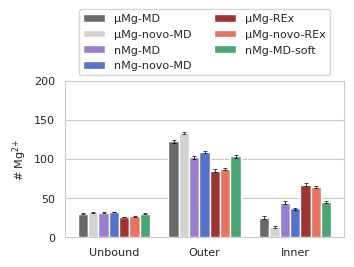

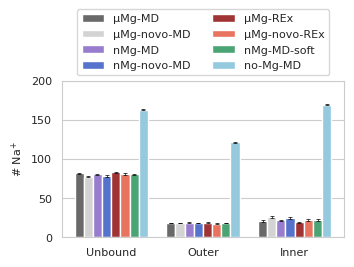

In [20]:
for ion in ['MG', 'NA']:
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))


    data = res.loc[ion, res.index.isin(simselection, level=1), 0, :].rename(index=simlabels).rename(index=dict(outer='Outer', inner='Inner', bulk='Unbound')).reset_index()
    data['sim'] = data['sim'].astype(CategoricalDtype(categories=labelselection, ordered=True)).cat.remove_unused_categories()

    type_order = ['Unbound', 'Outer', 'Inner']
    data['type'] = data['type'].astype(CategoricalDtype(categories=type_order, ordered=True))
    data = data.sort_values(['type', 'sim'])

    ax = sns.barplot(
        data=data,
        x='type',
        y='mean',
        hue='sim',
        palette=labelcolors,
        ax=ax,
    )

    for i, (sim, group) in enumerate(data.groupby('sim')):
        container = ax.containers[i]
        x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
        yerr = (group['mean'] - group['p025'], group['p095'] - group['mean'])
        ax.errorbar(
            x=x_coords,
            y=group['mean'],
            yerr=yerr,
            ls='none',
            c='black',
            capsize=1.5,
            elinewidth=0.5,
            capthick=0.5,
        )
    plt.legend(ncol=2, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))

    ax.set_ylabel(f"# {ionlabels[ion]}")
    ax.set_xlabel(None)
    ax.set_ylim(None, 200)
    fig.savefig(f'figures/bound_{ion.lower()}_barplot{suffix}.pdf')


### Denticity

In [21]:
res = df.groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'time', 'n_inner']).size().unstack(fill_value=0).stack().reset_index(name='count')
res['start_time'] = res['sim'].map(simstart)
res = res.query('time > start_time and n_inner > 0')
res = res.groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'n_inner'])['count'].agg(['mean', 'count'])
res = pd.DataFrame({
    'mean': res.groupby(['ion', 'sim', 'reptemp', 'n_inner']).apply(lambda x: np.average(x['mean'], weights=x['count'])),
    'ci': res.groupby(['ion', 'sim', 'reptemp', 'n_inner']).apply(lambda x: 
        bayesian_bootstrap(x['mean'], np.average, weights=x['count']).confidence_interval),
    })
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])

In [22]:
res

mean  \
ion sim                         reptemp n_inner              
MG  plain_md_7ez0_mMg_tip3p     0       1        13.657222   
                                        2         6.613056   
                                        3         2.796667   
                                        4         1.796389   
                                        5         0.010556   
...                                                    ...   
NA  replex_7ez0_noion_mMg_tip3p 7       8         0.006667   
                                        9         0.000000   
                                        10        0.000000   
                                        11        0.000000   
                                        12        0.000000   

                                                                                           ci  \
ion sim                         reptemp n_inner                                                 
MG  plain_md_7ez0_mMg_tip3p     0       1             (11.796660937658062, 15.88336512115689)   
                                        2              (5.910398303123877, 7.228594581129167)   
                                        3             (2.2576547349053824, 3.326601850418029)   
                                        4              (1.459040908580728, 2.027202154483389)   
                                        5        (0.006097331744131562, 0.014931419235038794)   
...                                                                                       ...   
NA  replex_7ez0_noion_mMg_tip3p 7       8        (0.0012969561250357575, 0.02294260303594626)   
                                        9                                          (0.0, 0.0)   
                                        10                                         (0.0, 0.0)   
                                        11                                         (0.0, 0.0)   
                                        12                                         (0.0, 0.0)   

                                                      p025       p095  
ion sim                         reptemp n_inner                        
MG  plain_md_7ez0_mMg_tip3p     0       1        11.796661  15.883365  
                                        2         5.910398   7.228595  
                                        3         2.257655   3.326602  
                                        4         1.459041   2.027202  
                                        5         0.006097   0.014931  
...                                                    ...        ...  
NA  replex_7ez0_noion_mMg_tip3p 7       8         0.001297   0.022943  
                                        9         0.000000   0.000000  
                                        10        0.000000   0.000000  
                                        11        0.000000   0.000000  
                                        12        0.000000   0.000000  

[516 rows x 4 columns]

/tmp/ipykernel_2258/1346461177.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_2258/1346461177.py:35: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/tmp/ipykernel_2258/1346461177.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_2258/1346461177.py:35: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


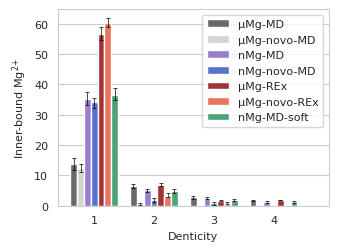

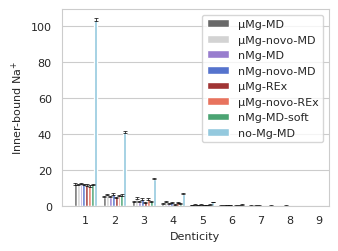

In [23]:
for ion in ['MG', 'NA']:
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

    data = res.query('mean > 0.01')
    data = data.loc[ion, data.index.isin(simselection, level=1), 0, :].rename(index=simlabels).reset_index()
    data['sim'] = data['sim'].astype(CategoricalDtype(categories=labelselection, ordered=True)).cat.remove_unused_categories()

    ax = sns.barplot(
        data=data,
        x='n_inner',
        y='mean',
        hue='sim',
        palette=labelcolors,
        ax=ax,
    )

    for i, (sim, group) in enumerate(data.groupby('sim')):
        container = ax.containers[i]
        x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
        yerr = (group['mean'] - group['p025'], group['p095'] - group['mean'])
        ax.errorbar(
            x=x_coords,
            y=group['mean'],
            yerr=yerr,
            ls='none',
            c='black',
            capsize=1.5,
            elinewidth=0.5,
            capthick=0.5,
        )
    ax.get_legend().set_title(None)

    ax.set_ylabel(f'Inner-bound {ionlabels[ion]}')
    ax.set_xlabel('Denticity')
    plt.tight_layout()
    fig.savefig(f'figures/bound_{ion.lower()}_denticity{suffix}.pdf')


## Ion counting

In [24]:
if compute:
    results = []

    methods = ['replex', 'plain_md']
    systems = ['7ez0', '7ez0_noion', '7ez0_nomg']
    forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
    replicates = range(2)
    replicas = range(8)

    radius = 40  # Å
    names = ['OW', 'MG', 'NA', 'CL']

    for method, sys, ff, replicate, rep in itertools.product(methods, systems, forcefields, replicates, replicas):
        path = PROJECT_DIR / f'{method}/{sys}/{ff}/replicate{replicate}/rep{rep+replicate*8:02d}'
        if not path.exists():
            continue
        
        u = mda.Universe(path / 'input.gro', path / 'run.xtc')

        if method == 'replex':
            reptemp = read_plumed(path / f'bias.COLVAR.{rep}')['bias.index'].astype(int)
            frames = (reptemp == 0).to_numpy()[::10]
            assert len(frames) == len(u.trajectory)
        else:
            frames = np.ones(len(u.trajectory), dtype=bool)
        sel = np.zeros(len(u.trajectory), dtype=bool)
        sel[::10] = True
        frames = frames & sel

        bulk_sels = {
            name: u.select_atoms(f"name {name}").select_atoms(f"not around {radius} global name P", updating=True)
            for name in names
        }

        tot_sels = {
            name: u.select_atoms(f"name {name}")
            for name in names
        }

        for ts in tqdm(u.trajectory[frames]):
            for name in names:
                results.append(
                    {
                        'sim': f"{method}_{sys}_{ff}",
                        'replicate': replicate if method == 'replex' else rep,
                        'replica': rep if method == 'replex' else 0,
                        'time': ts.time,
                        'name': name,
                        'n_bulk': len(bulk_sels[name]),
                        'n_tot': len(tot_sels[name]),
                        'volume': ts.volume,  # Å³
                    }
                )
                
    df = pd.DataFrame(results).set_index(['sim', 'time', 'name', 'replicate']).sort_index()
    df['c_bulk'] = 1000 * df['n_bulk'] / df['n_bulk'].loc[:, :, 'OW'] * 55.5
    df.to_csv('ion_count_bulk.csv')
else:
    df = pd.read_csv('ion_count_bulk.csv', na_filter=False)
df


,sim,time,name,replicate,replica,n_bulk,n_tot,volume,c_bulk
0,plain_md_7ez0_mMg_tip3p,0.0,CL,0,0,28,91,2.704782e+06,96.569724
1,plain_md_7ez0_mMg_tip3p,0.0,CL,1,0,32,91,2.698821e+06,109.656705
2,plain_md_7ez0_mMg_tip3p,0.0,CL,2,0,34,91,2.700061e+06,118.033402
3,plain_md_7ez0_mMg_tip3p,0.0,CL,3,0,39,91,2.697269e+06,135.662802
4,plain_md_7ez0_mMg_tip3p,0.0,CL,4,0,27,91,2.702006e+06,88.271678
...,...,...,...,...,...,...,...,...,...
103599,replex_7ez0_noion_mMg_tip3p,200000.0,MG,1,6,2,178,2.703253e+06,6.459497
103600,replex_7ez0_noion_mMg_tip3p,200000.0,NA,0,3,20,121,2.700709e+06,65.129379
103601,replex_7ez0_noion_mMg_tip3p,200000.0,NA,1,6,20,121,2.703253e+06,64.594972
103602,replex_7ez0_noion_mMg_tip3p,200000.0,OW,0,3,17043,85656,2.700709e+06,55500.000000


In [25]:

df.reset_index()

,index,sim,time,name,replicate,replica,n_bulk,n_tot,volume,c_bulk
0,0,plain_md_7ez0_mMg_tip3p,0.0,CL,0,0,28,91,2.704782e+06,96.569724
1,1,plain_md_7ez0_mMg_tip3p,0.0,CL,1,0,32,91,2.698821e+06,109.656705
2,2,plain_md_7ez0_mMg_tip3p,0.0,CL,2,0,34,91,2.700061e+06,118.033402
3,3,plain_md_7ez0_mMg_tip3p,0.0,CL,3,0,39,91,2.697269e+06,135.662802
4,4,plain_md_7ez0_mMg_tip3p,0.0,CL,4,0,27,91,2.702006e+06,88.271678
...,...,...,...,...,...,...,...,...,...,...
103599,103599,replex_7ez0_noion_mMg_tip3p,200000.0,MG,1,6,2,178,2.703253e+06,6.459497
103600,103600,replex_7ez0_noion_mMg_tip3p,200000.0,NA,0,3,20,121,2.700709e+06,65.129379
103601,103601,replex_7ez0_noion_mMg_tip3p,200000.0,NA,1,6,20,121,2.703253e+06,64.594972
103602,103602,replex_7ez0_noion_mMg_tip3p,200000.0,OW,0,3,17043,85656,2.700709e+06,55500.000000


In [26]:
res = df.reset_index()
res = res.loc[res['time'] / 1000 > res['sim'].map(simstart)]
res = res.groupby(['name', 'sim', 'replicate', 'replica']).agg(['mean', 'size'])['c_bulk']
res['weight'] = res['size'] / res['size'].groupby(['name', 'sim']).sum()
res = pd.DataFrame({
    'mean': res.groupby(['name', 'sim']).apply(lambda x: np.average(x['mean'], weights=x['weight'])),
    'ci': res.groupby(['name', 'sim']).apply(lambda x: 
        bayesian_bootstrap(x['mean'], np.average, weights=x['weight']).confidence_interval),
})
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])
res

mean  \
name sim                                           
CL   plain_md_7ez0_mMg_tip3p           71.521209   
     plain_md_7ez0_nMg_tip3p           71.392098   
     plain_md_7ez0_nMg_tip3p_soft      71.550890   
     plain_md_7ez0_noion_mMg_tip3p     71.659559   
     plain_md_7ez0_noion_nMg_tip3p     71.217002   
     plain_md_7ez0_nomg_mMg_tip3p      62.425751   
     replex_7ez0_mMg_tip3p             71.210789   
     replex_7ez0_noion_mMg_tip3p       70.032808   
MG   plain_md_7ez0_mMg_tip3p           12.003947   
     plain_md_7ez0_nMg_tip3p           12.688453   
     plain_md_7ez0_nMg_tip3p_soft      12.293085   
     plain_md_7ez0_noion_mMg_tip3p     13.516202   
     plain_md_7ez0_noion_nMg_tip3p     12.958638   
     plain_md_7ez0_nomg_mMg_tip3p       0.000000   
     replex_7ez0_mMg_tip3p             10.855885   
     replex_7ez0_noion_mMg_tip3p       12.373976   
NA   plain_md_7ez0_mMg_tip3p           50.231832   
     plain_md_7ez0_nMg_tip3p           49.134052   
     plain_md_7ez0_nMg_tip3p_soft      49.516129   
     plain_md_7ez0_noion_mMg_tip3p     47.409873   
     plain_md_7ez0_noion_nMg_tip3p     47.722362   
     plain_md_7ez0_nomg_mMg_tip3p      71.064944   
     replex_7ez0_mMg_tip3p             51.571731   
     replex_7ez0_noion_mMg_tip3p       49.526560   
OW   plain_md_7ez0_mMg_tip3p        55500.000000   
     plain_md_7ez0_nMg_tip3p        55500.000000   
     plain_md_7ez0_nMg_tip3p_soft   55500.000000   
     plain_md_7ez0_noion_mMg_tip3p  55500.000000   
     plain_md_7ez0_noion_nMg_tip3p  55500.000000   
     plain_md_7ez0_nomg_mMg_tip3p   55500.000000   
     replex_7ez0_mMg_tip3p          55500.000000   
     replex_7ez0_noion_mMg_tip3p    55500.000000   

                                                                          ci  \
name sim                                                                       
CL   plain_md_7ez0_mMg_tip3p          (71.36918143739905, 71.71229155683993)   
     plain_md_7ez0_nMg_tip3p           (71.0106781520465, 71.75196758605681)   
     plain_md_7ez0_nMg_tip3p_soft      (71.1576698004827, 71.91709152909381)   
     plain_md_7ez0_noion_mMg_tip3p     (70.8880911663206, 72.34845648038122)   
     plain_md_7ez0_noion_nMg_tip3p     (70.80544262785659, 71.6974896616341)   
     plain_md_7ez0_nomg_mMg_tip3p     (61.81624798367721, 63.44558933558635)   
     replex_7ez0_mMg_tip3p            (70.13009674314118, 72.38528856250844)   
     replex_7ez0_noion_mMg_tip3p      (68.52182096699963, 72.09662765671469)   
MG   plain_md_7ez0_mMg_tip3p         (11.510343696668224, 12.37305821115211)   
     plain_md_7ez0_nMg_tip3p        (12.414498684098549, 12.982773501330557)   
     plain_md_7ez0_nMg_tip3p_soft    (12.062998572345077, 12.48615567795351)   
     plain_md_7ez0_noion_mMg_tip3p   (12.704982845937266, 14.10300384507412)   
     plain_md_7ez0_noion_nMg_tip3p  (12.572909063520308, 13.394301240367794)   
     plain_md_7ez0_nomg_mMg_tip3p                                 (0.0, 0.0)   
     replex_7ez0_mMg_tip3p          (10.396505998557931, 11.231515946950445)   
     replex_7ez0_noion_mMg_tip3p     (11.50894160670247, 13.249862322975963)   
NA   plain_md_7ez0_mMg_tip3p         (49.22504344043064, 51.251250539106174)   
     plain_md_7ez0_nMg_tip3p          (48.2379448657683, 49.950716982434315)   
     plain_md_7ez0_nMg_tip3p_soft     (48.83383561555558, 50.23836624033403)   
     plain_md_7ez0_noion_mMg_tip3p    (46.2589767018351, 48.863170766698964)   
     plain_md_7ez0_noion_nMg_tip3p    (47.00362581970661, 48.67221988594679)   
     plain_md_7ez0_nomg_mMg_tip3p      (70.58926493286334, 71.6367045719897)   
     replex_7ez0_mMg_tip3p           (50.23410780226459, 52.781801766078694)   
     replex_7ez0_noion_mMg_tip3p       (48.041067852953, 50.961160205154236)   
OW   plain_md_7ez0_mMg_tip3p         (55499.99999999999, 55500.000000000015)   
     plain_md_7ez0_nMg_tip3p         (55499.99999999999, 55500.000000000015)   
     plain_md_7ez0_nMg_tip3p_soft  

/tmp/ipykernel_2258/756244804.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_2258/756244804.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([


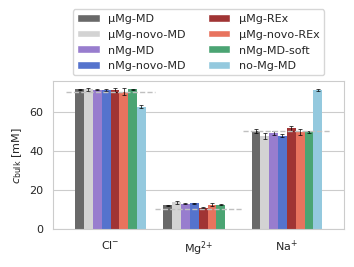

In [27]:
target_cbulk = {
    'CL': 70,
    'MG': 10,
    'NA': 50,
}

fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

data = res.query('name != "OW"').rename(index=simlabels).reset_index()
data['sim'] = data['sim'].astype(CategoricalDtype(categories=labelselection, ordered=True)).cat.remove_unused_categories()

ax = sns.barplot(
    data=data,
    x='name',
    y='mean',
    hue='sim',
    palette=labelcolors,
    ax=ax,
    linestyle='none',
)

for i, (sim, group) in enumerate(data.groupby('sim')):
    container = ax.containers[i]
    x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
    yerr = (group['mean'] - group['p025'], group['p095'] - group['mean'])
    ax.errorbar(
        x=x_coords,
        y=group['mean'],
        yerr=yerr,
        ls='none',
        c='black',
        capsize=1.5,
        elinewidth=0.5,
        capthick=0.5,
    )

for i, (name, group) in enumerate(data.groupby('name')):
    ax.hlines(target_cbulk[name], -0.5 + i, 0.5 + i,  ls='dashed', lw=1, color='silver', zorder=+10)
plt.legend(ncol=2, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))

ax.set_xticklabels([
    ionlabels[t.get_text()] for t in ax.get_xticklabels()
])

ax.set_ylabel(f'$c_\mathrm{{bulk}}$ [mM]')
ax.set_xlabel(None)
fig.savefig(f'figures/bulk_conc.pdf')

In [28]:
df['n_excess'] = df['n_tot'] - 1e-3 * df['c_bulk'] * 1e-27 * df['volume'] * Avogadro

In [29]:
df

,sim,time,name,replicate,replica,n_bulk,n_tot,volume,c_bulk,n_excess
0,plain_md_7ez0_mMg_tip3p,0.0,CL,0,0,28,91,2.704782e+06,96.569724,-66.298324
1,plain_md_7ez0_mMg_tip3p,0.0,CL,1,0,32,91,2.698821e+06,109.656705,-87.221537
2,plain_md_7ez0_mMg_tip3p,0.0,CL,2,0,34,91,2.700061e+06,118.033402,-100.924075
3,plain_md_7ez0_mMg_tip3p,0.0,CL,3,0,39,91,2.697269e+06,135.662802,-129.361621
4,plain_md_7ez0_mMg_tip3p,0.0,CL,4,0,27,91,2.702006e+06,88.271678,-52.634441
...,...,...,...,...,...,...,...,...,...,...
103599,replex_7ez0_noion_mMg_tip3p,200000.0,MG,1,6,2,178,2.703253e+06,6.459497,167.484344
103600,replex_7ez0_noion_mMg_tip3p,200000.0,NA,0,3,20,121,2.700709e+06,65.129379,15.073240
103601,replex_7ez0_noion_mMg_tip3p,200000.0,NA,1,6,20,121,2.703253e+06,64.594972,15.843440
103602,replex_7ez0_noion_mMg_tip3p,200000.0,OW,0,3,17043,85656,2.700709e+06,55500.000000,-4609.488345


In [30]:
res = df.reset_index()
res = res.loc[res['time'] / 1000 > res['sim'].map(simstart)]
res = res.groupby(['name', 'sim', 'replicate', 'replica']).agg(['mean', 'size'])['n_excess']
out = pd.concat([2*res.loc['MG'] + res.loc['NA'] - res.loc['CL']], keys=['ztot'], names=['name'])
res = pd.concat([res, out])
res['weight'] = res['size'] / res['size'].groupby(['name', 'sim']).sum()
res = pd.DataFrame({
    'mean': res.groupby(['name', 'sim']).apply(lambda x: np.average(x['mean'], weights=x['weight'])),
    'ci': res.groupby(['name', 'sim']).apply(lambda x: 
        bayesian_bootstrap(x['mean'], np.average, weights=x['weight']).confidence_interval),
})
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])
res.round(2)

mean  \
name sim                                      
CL   plain_md_7ez0_mMg_tip3p         -25.32   
     plain_md_7ez0_nMg_tip3p         -25.12   
     plain_md_7ez0_nMg_tip3p_soft    -25.39   
     plain_md_7ez0_noion_mMg_tip3p   -25.44   
     plain_md_7ez0_noion_nMg_tip3p   -24.73   
     plain_md_7ez0_nomg_mMg_tip3p    -34.43   
     replex_7ez0_mMg_tip3p           -24.85   
     replex_7ez0_noion_mMg_tip3p     -22.84   
MG   plain_md_7ez0_mMg_tip3p         158.48   
     plain_md_7ez0_nMg_tip3p         157.36   
     plain_md_7ez0_nMg_tip3p_soft    158.00   
     plain_md_7ez0_noion_mMg_tip3p   156.04   
     plain_md_7ez0_noion_nMg_tip3p   156.94   
     plain_md_7ez0_nomg_mMg_tip3p      0.00   
     replex_7ez0_mMg_tip3p           160.34   
     replex_7ez0_noion_mMg_tip3p     157.89   
NA   plain_md_7ez0_mMg_tip3p          39.31   
     plain_md_7ez0_nMg_tip3p          41.08   
     plain_md_7ez0_nMg_tip3p_soft     40.45   
     plain_md_7ez0_noion_mMg_tip3p    43.96   
     plain_md_7ez0_noion_nMg_tip3p    43.45   
     plain_md_7ez0_nomg_mMg_tip3p    337.53   
     replex_7ez0_mMg_tip3p            37.10   
     replex_7ez0_noion_mMg_tip3p      40.49   
OW   plain_md_7ez0_mMg_tip3p       -4532.22   
     plain_md_7ez0_nMg_tip3p       -4540.05   
     plain_md_7ez0_nMg_tip3p_soft  -4553.77   
     plain_md_7ez0_noion_mMg_tip3p -4527.51   
     plain_md_7ez0_noion_nMg_tip3p -4532.83   
     plain_md_7ez0_nomg_mMg_tip3p  -4653.78   
     replex_7ez0_mMg_tip3p         -4560.86   
     replex_7ez0_noion_mMg_tip3p   -4562.13   
ztot plain_md_7ez0_mMg_tip3p         381.58   
     plain_md_7ez0_nMg_tip3p         380.93   
     plain_md_7ez0_nMg_tip3p_soft    381.85   
     plain_md_7ez0_noion_mMg_tip3p   381.48   
     plain_md_7ez0_noion_nMg_tip3p   382.06   
     plain_md_7ez0_nomg_mMg_tip3p    371.96   
     replex_7ez0_mMg_tip3p           382.62   
     replex_7ez0_noion_mMg_tip3p     379.11   

                                                                            ci  \
name sim                                                                         
CL   plain_md_7ez0_mMg_tip3p        (-25.645016872081122, -25.011357115287556)   
     plain_md_7ez0_nMg_tip3p         (-25.69859698584136, -24.386468749933073)   
     plain_md_7ez0_nMg_tip3p_soft   (-26.088824097448782, -24.809809728084673)   
     plain_md_7ez0_noion_mMg_tip3p   (-26.49960108894234, -24.194656322767845)   
     plain_md_7ez0_noion_nMg_tip3p   (-25.467743739769436, -24.08232098106165)   
     plain_md_7ez0_nomg_mMg_tip3p    (-35.612474533531056, -33.55962012796482)   
     replex_7ez0_mMg_tip3p           (-26.982168854476843, -23.16065023086322)   
     replex_7ez0_noion_mMg_tip3p     (-25.03152507116527, -20.577739920164532)   
MG   plain_md_7ez0_mMg_tip3p            (157.880470479066, 159.24516089446112)   
     plain_md_7ez0_nMg_tip3p            (156.911694560622, 157.79811231651814)   
     plain_md_7ez0_nMg_tip3p_soft       (157.691547562301, 158.36308272634454)   
     plain_md_7ez0_noion_mMg_tip3p    (155.05314046683998, 157.61840801544014)   
     plain_md_7ez0_noion_nMg_tip3p     (156.30214048840142, 157.5014237513249)   
     plain_md_7ez0_nomg_mMg_tip3p                                   (0.0, 0.0)   
     replex_7ez0_mMg_tip3p            (159.69058884563535, 161.05394300817204)   
     replex_7ez0_noion_mMg_tip3p         (156.0282256210372, 159.265045219515)   
NA   plain_md_7ez0_mMg_tip3p            (37.61077860985306, 40.99719261090114)   
     plain_md_7ez0_nMg_tip3p            (39.66606110419417, 42.42625208996303)   
     plain_md_7ez0_nMg_tip3p_soft     (39.443075060322236, 41.594337602839126)   
     plain_md_7ez0_noion_mMg_tip3p        (41.605684199853, 45.78892490618419)   
     plain_md_7ez0_noion_nMg_tip3p      (42.3555726614631, 44.892803075861785)   
     plain_md_7ez0_nomg_mMg_tip3p      (336.6665748452417, 338.40185302937925)   
     replex_7ez0_mMg_tip3p              (35.26053678909822, 38.83231109870796)   
     replex_7e

/tmp/ipykernel_2258/3013085752.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_2258/3013085752.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([


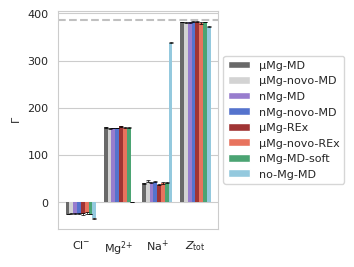

In [31]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

data = res.query('name != "OW"').rename(index=simlabels).reset_index()
data['sim'] = data['sim'].astype(CategoricalDtype(categories=labelselection, ordered=True)).cat.remove_unused_categories()

ax = sns.barplot(
    data=data,
    x='name',
    y='mean',
    hue='sim',
    palette=labelcolors,
    ax=ax,
    linestyle='none',
)

for i, (sim, group) in enumerate(data.groupby('sim')):
    container = ax.containers[i]
    x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
    yerr = (group['mean'] - group['p025'], group['p095'] - group['mean'])
    ax.errorbar(
        x=x_coords,
        y=group['mean'],
        yerr=yerr,
        ls='none',
        c='black',
        capsize=1.5,
        elinewidth=0.5,
        capthick=0.5,
    )
ax.axhline(386, color='silver', linestyle='dashed')
plt.legend(title=None, loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_xticklabels([
    ionlabels[t.get_text()] for t in ax.get_xticklabels()
])
ax.set_ylabel(f'$\Gamma$')
ax.set_xlabel(None)
fig.savefig(f'figures/ion_counting.pdf')

In [32]:
# Competition ratio

data = data.set_index(['name', 'sim'])
data.loc['MG']['mean'] / data.loc['NA']['mean']

sim
μMg-MD          4.031933
nMg-MD          3.830264
nMg-MD-soft     3.906034
μMg-novo-MD     3.549394
nMg-novo-MD     3.612003
no-Mg-MD        0.000000
μMg-REx         4.322115
μMg-novo-REx    3.899185
Name: mean, dtype: float64

### Residue distribution

In [33]:
# Load binding motif data
ions = ['NA', 'MG']
df = pd.DataFrame()

# Replex
method = 'replex'
systems = ['7ez0', '7ez0_noion']
ff = 'mMg_tip3p'
replicates = [0, 1]
repids = range(8)

for ion in ions:
    for sys in systems:
        for rep, i in itertools.product(replicates, repids):
            _df = pd.read_parquet(
                PROJECT_DIR / f'replex/{sys}/{ff}/replicate{rep}/rep{i+8*rep:02d}/{ion}_motifs.parquet',
                columns=['time', 'n_inner', 'inner_names', 'inner_resids'],
            )
            _df = _df.loc[_df['time'].astype(int) % 1000 == 0]
            _df = _df.assign(ion=ion, sim=f"{method}_{sys}_{ff}", system=sys, replicate=rep, repid=i)
            colvar = read_plumed(PROJECT_DIR / f'replex/{sys}/{ff}/replicate{rep}/rep{i+8*rep:02d}/bias.COLVAR.{i}')
            colvar['time'] = colvar['time'].astype(int)
            _df['reptemp'] = colvar.set_index('time').loc[_df['time'].astype(int), 'bias.index'].astype(int).values
            _df['time'] = _df['time'] / 1000  # ns

            df = pd.concat([df, _df])

# Plain MD
method = 'plain_md'
systems = ['7ez0', '7ez0_noion', '7ez0_nomg']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
replicates = range(8)

for ion in ions:
    for sys, ff in itertools.product(systems, forcefields):
        for rep in replicates:
            path = PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/rep{rep:02d}/{ion}_motifs.parquet'
            if not path.exists():
                continue
            _df = pd.read_parquet(
                path,
                columns=['time', 'n_inner', 'inner_names', 'inner_resids'],
            )
            _df = _df.assign(ion=ion, sim=f"{method}_{sys}_{ff}", system=sys, replicate=rep, repid=0)
            _df = _df.loc[_df['time'].astype(int) % 1000 == 0]
            _df['reptemp'] = 0
            _df['time'] = _df['time'] / 1000  # ns

            df = pd.concat([df, _df])

In [34]:
df.head()

,time,n_inner,inner_names,inner_resids,ion,sim,system,replicate,repid,reptemp
0,0.0,0,[],[],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
1,0.0,0,[],[],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
2,0.0,0,[],[],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
3,0.0,1,[O2'],[293],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
4,0.0,0,[],[],NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0


In [35]:
x = df.loc[df['time'] > df['sim'].map(simstart)].copy()
x = x.query('reptemp == 0')
n_frames = x.groupby(['sim', 'replicate', 'repid'])['time'].nunique()
cols = [col for col in x.columns if col.startswith('inner')]
x = x.query("n_inner != 0")
x = x.explode(cols)
x = x.query("inner_names == 'OP2' or inner_names == 'OP1'")
counts = x.groupby(['sim', 'replicate', 'repid', 'ion', 'inner_resids', 'inner_names']).size()

In [36]:
counts

sim                          replicate  repid  ion  inner_resids  inner_names
plain_md_7ez0_mMg_tip3p      0          0      MG   52            OP2            273
                                                    77            OP2            450
                                                    84            OP2            363
                                                    114           OP2            450
                                                    122           OP1             12
                                                                                ... 
replex_7ez0_noion_mMg_tip3p  1          7      NA   395           OP1              1
                                                    403           OP1              1
                                                    404           OP1              2
                                                                  OP2              1
                                                    408           OP1   

In [37]:
x = counts.unstack('inner_names', fill_value=0).unstack('inner_resids', fill_value=0).unstack('ion', fill_value=0).stack().stack().stack().to_frame(name='count')
x['n_frames'] = n_frames
x['weights'] = x['n_frames'] / x.groupby(['sim', 'ion', 'inner_resids', 'inner_names'])['n_frames'].sum()
x['p'] = x['count'] / x['n_frames']

/tmp/ipykernel_2258/646398015.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  x = counts.unstack('inner_names', fill_value=0).unstack('inner_resids', fill_value=0).unstack('ion', fill_value=0).stack().stack().stack().to_frame(name='count')
/tmp/ipykernel_2258/646398015.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  x = counts.unstack('inner_names', fill_value=0).unstack('inner_resids', fill_value=0).unstack('ion', fill_value=0).stack().stack().stack().to_frame(name='count')


In [38]:
res = pd.DataFrame({
    'mean': x.groupby(['sim', 'ion', 'inner_resids', 'inner_names']).apply(lambda x: np.average(x['p'], weights=x['weights'])),
    'ci': x.groupby(['sim', 'ion', 'inner_resids', 'inner_names']).apply(lambda x: 
        bayesian_bootstrap(x['p'], np.average, weights=x['weights'], n_resamples=20).confidence_interval),
    })
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])

In [39]:
ref_7ez0 = pd.read_parquet(PROJECT_DIR / 'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet', columns=['inner_names', 'inner_resids'])
ref_7ez0 = ref_7ez0.explode(['inner_resids', 'inner_names'])
ref_9cbu = pd.read_parquet(PROJECT_DIR / 'structures/9cbu/MG_motifs_summary.parquet', columns=['inner_names', 'inner_resids'])
ref_9cbu = ref_9cbu.explode(['inner_resids', 'inner_names'])

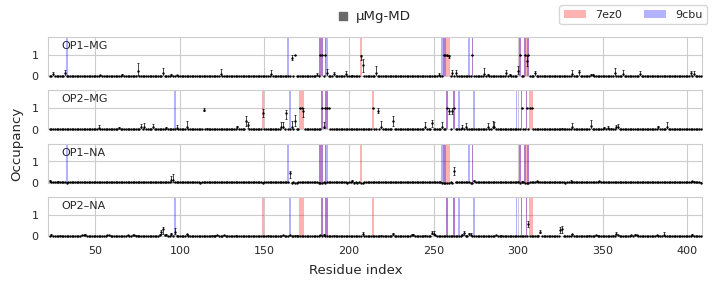

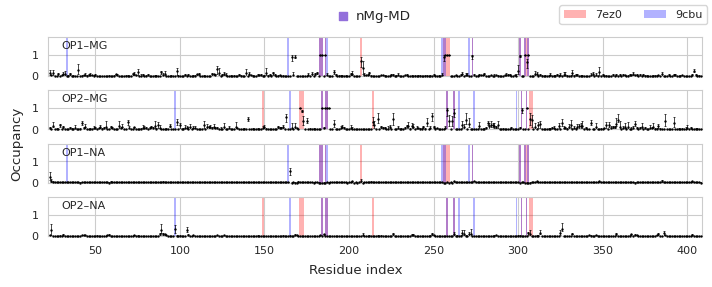

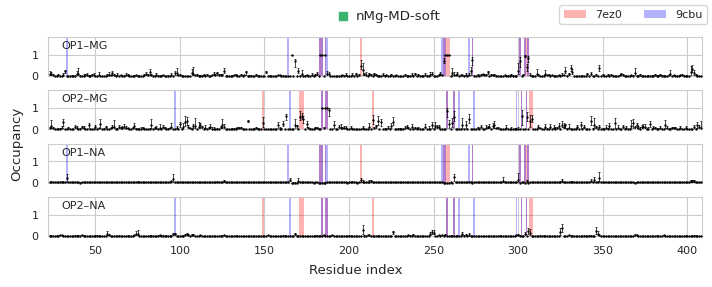

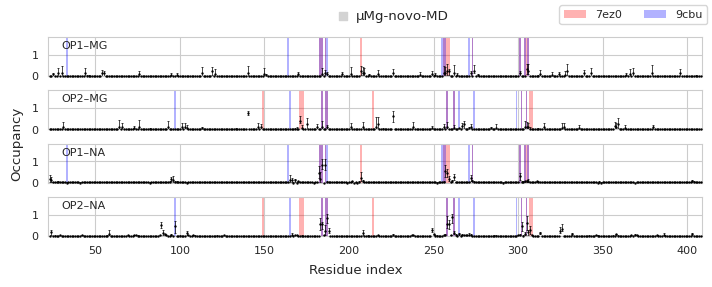

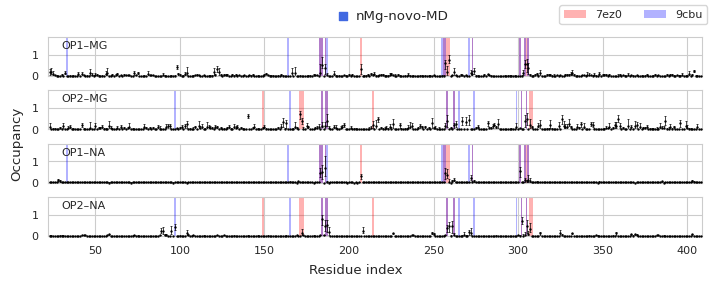

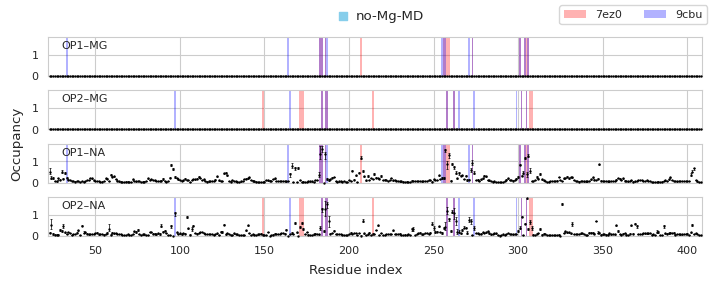

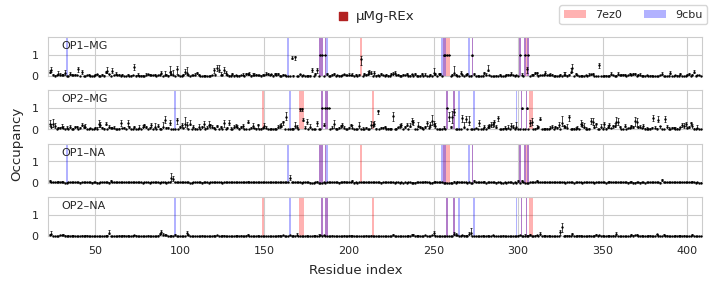

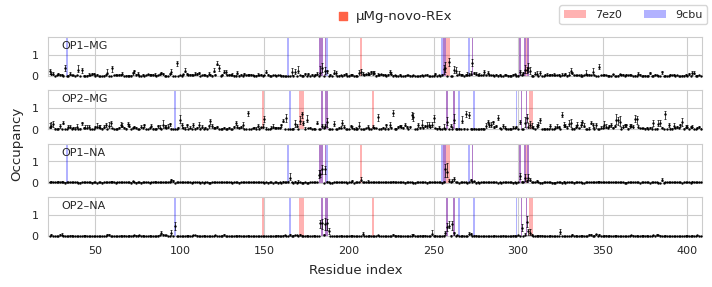

In [40]:
from matplotlib import colors

for sim, group in res.groupby('sim'):
    fig, axarr = plt.subplots(nrows=4, figsize=(17.8*cm,7*cm), sharex=True, sharey=True)

    for ax, (ion, name) in zip(axarr, itertools.product(['MG', 'NA'], ['OP1', 'OP2'])):
        data = group.loc[sim, ion, :, name]
        yerr = ((data['mean'] - data['p025']).clip(0, None), (data['p095'] - data['mean']).clip(0, None))
        ax.errorbar(data.index, data['mean'], yerr=yerr, linestyle='none', marker='none', capsize=1, elinewidth=0.5, ecolor='black', capthick=0.5)
        
        ref_resids = ref_7ez0.query('inner_names == @name')['inner_resids']
        for i in ref_resids.values:
            h1 = ax.axvspan(i-0.5, i+0.5, facecolor='red', edgecolor='none', alpha=0.3)
        ref_resids = ref_9cbu.query('inner_names == @name')['inner_resids']
        for i in ref_resids.values:
            h2 = ax.axvspan(i-0.5, i+0.5, facecolor='blue', edgecolor='none', alpha=0.3)

        ax.scatter(data.index, data['mean'], marker='.', c='black', s=2, zorder=10, clip_on=False)
        ax.text(0.02, 0.9, f"{name}–{ion}", ha='left', va='top', transform=ax.transAxes)

    fig.legend([h1, h2], ['7ez0', '9cbu'], ncol=2, loc='outside upper right')
    title = fig.suptitle(f"{simlabels[sim]}", ha='left')

    # Ugly hack
    axarr[0].scatter(0.45, 1.55, transform=axarr[0].transAxes, clip_on=False, marker='s', color=simcolors[sim])

    fig.supylabel(r"Occupancy")
    fig.supxlabel(f"Residue index")
    
    plt.ylim(0, res['p095'].max())
    plt.xlim(data.index.min()-1, data.index.max()+1)
    plt.savefig(f"figures/sequence_bound_{sim}.pdf")
    

### RDFs

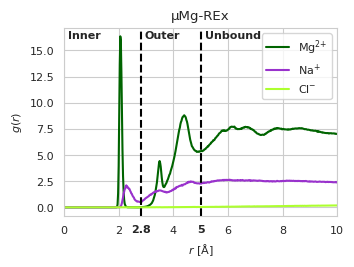

In [41]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))


for ion in ['MG', 'NA', 'CL']:
    rdf = np.loadtxt(PROJECT_DIR / f'replex/7ez0/mMg_tip3p/replicate0/remux/0_{ion}_RNA_rdf.xvg', comments=['#', '@'])
    ax.plot(rdf[:, 0]*10, rdf[:, 1], color=ioncolors[ion], label=ionlabels[ion])
    ax.set_xlim(0, 10)
ax.axvline(2.8, color='black', ls='dashed')
ax.axvline(5, color='black', ls='dashed')
ax.annotate("Inner", xy=(0, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("Outer", xy=(2.8, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("Unbound", xy=(5, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("2.8", xy=(2.8, 0), xytext=(0, -6), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='center', fontweight='bold')
ax.annotate("5", xy=(5, 0), xytext=(0, -6), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='center', fontweight='bold')

ax.set_ylabel(r'$g(r)$')
ax.set_xlabel(r'$r$ [Å]')
ax.legend()
ax.set_title(simlabels['replex_7ez0_mMg_tip3p'])
fig.savefig('figures/rdfs_mMg.pdf')

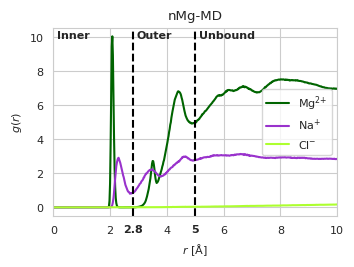

In [42]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

for ion in ['MG', 'NA', 'CL']:
    rdf = np.loadtxt(PROJECT_DIR / f'plain_md/7ez0/nMg_tip3p/replicate0/rep00/{ion}_RNA_rdf.xvg', comments=['#', '@'])
    ax.plot(rdf[:, 0]*10, rdf[:, 1], color=ioncolors[ion], label=ionlabels[ion])
    ax.set_xlim(0, 10)
ax.axvline(2.8, color='black', ls='dashed')
ax.axvline(5, color='black', ls='dashed')
ax.annotate("Inner", xy=(0, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("Outer", xy=(2.8, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("Unbound", xy=(5, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("2.8", xy=(2.8, 0), xytext=(0, -6), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='center', fontweight='bold')
ax.annotate("5", xy=(5, 0), xytext=(0, -6), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='center', fontweight='bold')

ax.set_ylabel(r'$g(r)$')
ax.set_xlabel(r'$r$ [Å]')
ax.legend()
ax.set_title(simlabels['plain_md_7ez0_nMg_tip3p'])
fig.savefig('figures/rdfs_nMg.pdf')

In [43]:
from matplotlib import colors

for sim in simselection:
    print(f"{{\cellcolor[HTML]{{{colors.to_hex(simcolors[sim])[1:]}}}}} {simlabels[sim]}")

{\cellcolor[HTML]{696969}} μMg-MD
{\cellcolor[HTML]{d3d3d3}} μMg-novo-MD
{\cellcolor[HTML]{9370db}} nMg-MD
{\cellcolor[HTML]{4169e1}} nMg-novo-MD
{\cellcolor[HTML]{b22222}} μMg-REx
{\cellcolor[HTML]{ff6347}} μMg-novo-REx
{\cellcolor[HTML]{3cb371}} nMg-MD-soft
{\cellcolor[HTML]{87ceeb}} no-Mg-MD


In [44]:
colors.to_hex('dimgray')

'#696969'